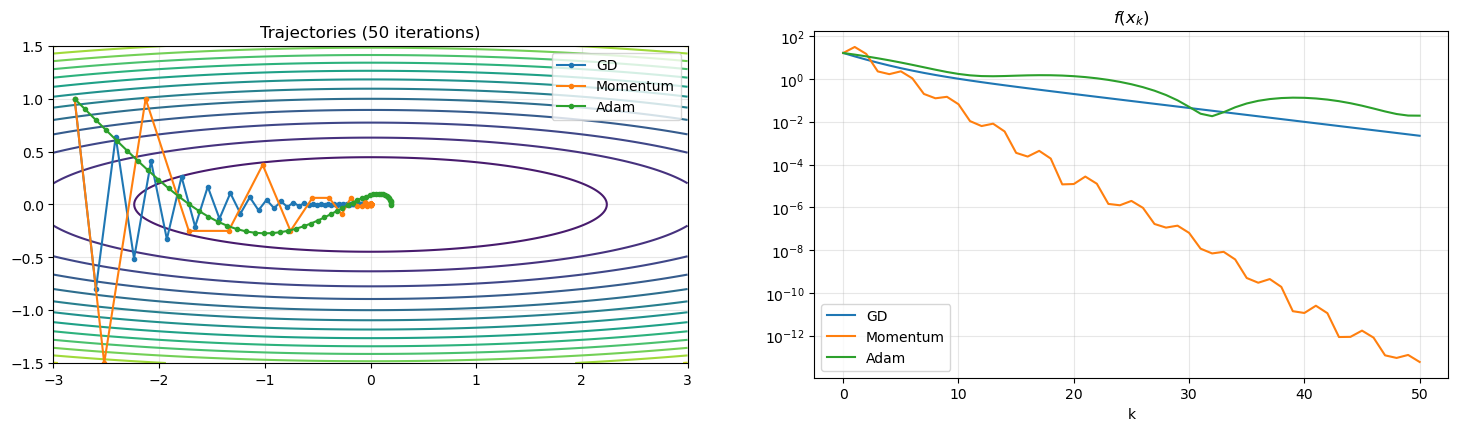

In [1]:
import numpy as np
import matplotlib.pyplot as plt

lam = 25
f = lambda x: 0.5 * (x[0]**2 + lam * x[1]**2)
grad_f = lambda x: np.array([x[0], lam * x[1]])

def run_gd(x0, eta, maxit):
    x = x0.copy(); xs = [x.copy()]
    for k in range(maxit):
        x = x - eta * grad_f(x)
        xs.append(x.copy())
    return np.array(xs)

def run_momentum(x0, eta, beta, maxit):
    x = x0.copy(); m = np.zeros_like(x); xs = [x.copy()]
    for k in range(maxit):
        m = beta * m + grad_f(x)
        x = x - eta * m
        xs.append(x.copy())
    return np.array(xs)

def run_adam(x0, eta, maxit, beta1=0.9, beta2=0.999, eps=1e-8):
    x = x0.copy(); m = np.zeros_like(x); v = np.zeros_like(x); xs = [x.copy()]
    for k in range(maxit):
        g = grad_f(x)
        m = beta1 * m + (1 - beta1) * g
        v = beta2 * v + (1 - beta2) * g**2
        m_hat = m / (1 - beta1**(k + 1))
        v_hat = v / (1 - beta2**(k + 1))
        x = x - eta * m_hat / (np.sqrt(v_hat) + eps)
        xs.append(x.copy())
    return np.array(xs)

x0 = np.array([-2.8, 1.0])
maxit = 50
trajectories = {
    "GD": run_gd(x0, eta=1.8 / lam, maxit=maxit),
    "Momentum": run_momentum(x0, eta=2.5 / lam, beta=0.5, maxit=maxit),
    "Adam": run_adam(x0, eta=0.1, maxit=maxit),
}

xx1, xx2 = np.meshgrid(np.linspace(-3, 3, 300), np.linspace(-1.5, 1.5, 300))
fig, axes = plt.subplots(1, 2, figsize=(18, 4.5))
axes[0].contour(xx1, xx2, 0.5 * (xx1**2 + lam * xx2**2), levels=15, cmap="viridis")
for name, xs in trajectories.items():
    axes[0].plot(xs[:, 0], xs[:, 1], 'o-', ms=3, label=name)
    axes[1].semilogy([f(x) for x in xs], label=name)
axes[0].set_aspect("equal")
axes[0].set_title(f"Trajectories ({maxit} iterations)")
axes[1].set_title("$f(x_k)$")
axes[1].set_xlabel("k")
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)
plt.show()

In [2]:
import os
import gzip
import urllib.request

URL = "https://github.com/zalandoresearch/fashion-mnist/raw/master/data/fashion/"
FILES = {
    "X_train": "train-images-idx3-ubyte.gz",
    "y_train": "train-labels-idx1-ubyte.gz",
    "X_test": "t10k-images-idx3-ubyte.gz",
    "y_test": "t10k-labels-idx1-ubyte.gz",
}
DATA_DIR = "data/fashion_mnist"

os.makedirs(DATA_DIR, exist_ok=True)
for name, filename in FILES.items():
    path = os.path.join(DATA_DIR, filename)
    if not os.path.exists(path):
        print(f"Downloading {filename}...")
        urllib.request.urlretrieve(URL + filename, path)
    print(f"{filename}: {os.path.getsize(path) / 1e6:.1f} MB")

train-images-idx3-ubyte.gz: 26.4 MB
train-labels-idx1-ubyte.gz: 0.0 MB
t10k-images-idx3-ubyte.gz: 4.4 MB
t10k-labels-idx1-ubyte.gz: 0.0 MB


In [3]:
def load_images(path):
    with gzip.open(path, "rb") as f:
        data = np.frombuffer(f.read(), dtype=np.uint8, offset=16)
    return data.reshape(-1, 28, 28)

def load_labels(path):
    with gzip.open(path, "rb") as f:
        data = np.frombuffer(f.read(), dtype=np.uint8, offset=8)
    return data.astype(int)

X_train_full = load_images(os.path.join(DATA_DIR, FILES["X_train"]))
y_train_full = load_labels(os.path.join(DATA_DIR, FILES["y_train"]))
X_test = load_images(os.path.join(DATA_DIR, FILES["X_test"]))
y_test = load_labels(os.path.join(DATA_DIR, FILES["y_test"]))

print(f"Training images: {X_train_full.shape}, dtype: {X_train_full.dtype}")
print(f"Training labels: {y_train_full.shape}, values: {np.unique(y_train_full)}")
print(f"Test images: {X_test.shape}")
print(f"Number of training images per class: {np.bincount(y_train_full)}")

Training images: (60000, 28, 28), dtype: uint8
Training labels: (60000,), values: [0 1 2 3 4 5 6 7 8 9]
Test images: (10000, 28, 28)
Number of training images per class: [6000 6000 6000 6000 6000 6000 6000 6000 6000 6000]


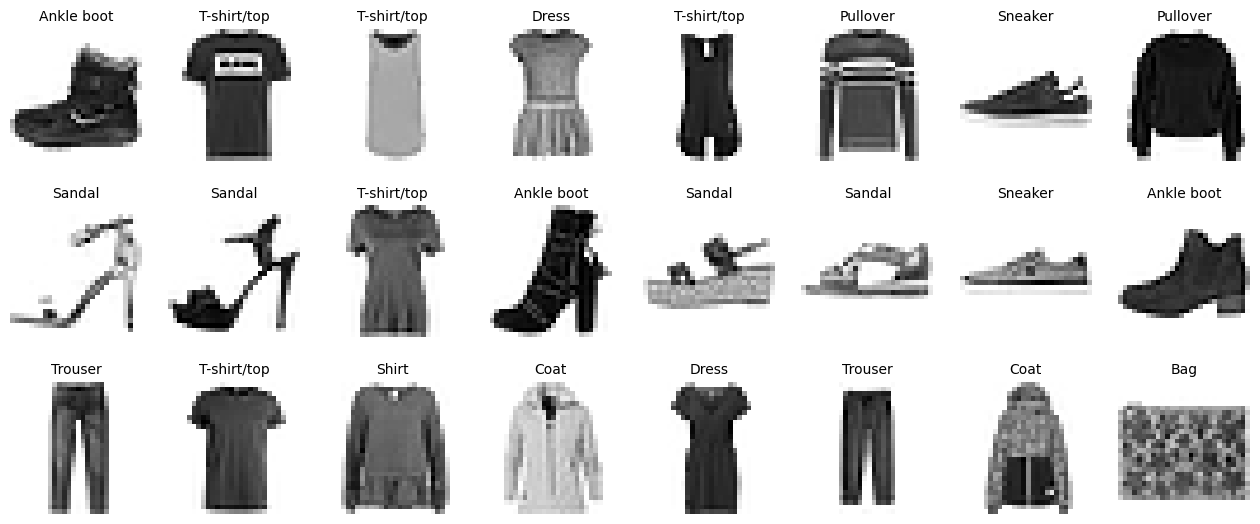

In [4]:
CLASSES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
           "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

fig, axes = plt.subplots(3, 8, figsize=(16, 6.5))
for ax, i in zip(axes.ravel(), range(24)):
    ax.imshow(X_train_full[i], cmap="gray_r")
    ax.set_title(CLASSES[y_train_full[i]], fontsize=10)
    ax.axis("off")
plt.show()

In [5]:
# 0. Select the two classes of the binary task
CLASS_0, CLASS_1 = 0, 6  # T-shirt/top vs. Shirt
CLASS_NAMES = ["T-shirt/top", "Shirt"]

mask = np.isin(y_train_full, [CLASS_0, CLASS_1])
X_train_full, y_train_full = X_train_full[mask], (y_train_full[mask] == CLASS_1).astype(int)
mask = np.isin(y_test, [CLASS_0, CLASS_1])
X_test, y_test = X_test[mask], (y_test[mask] == CLASS_1).astype(int)

# 1. Flattening and conversion to float in [0, 1]
X_train_full = X_train_full.reshape(-1, 784).astype(np.float64) / 255.0
X_test = X_test.reshape(-1, 784).astype(np.float64) / 255.0

# 3. Train / validation split
N_val = 2000
X_train, y_train = X_train_full[:-N_val], y_train_full[:-N_val]
X_val, y_val = X_train_full[-N_val:], y_train_full[-N_val:]

# 2. Standardization (statistics computed on the training set only!)
mu, sigma = X_train.mean(), X_train.std()
X_train = (X_train - mu) / sigma
X_val = (X_val - mu) / sigma
X_test = (X_test - mu) / sigma

# 4. Labels as column vectors
Y_train = y_train.reshape(-1, 1).astype(float)
Y_val = y_val.reshape(-1, 1).astype(float)
Y_test = y_test.reshape(-1, 1).astype(float)

print(f"Train: X {X_train.shape}, Y {Y_train.shape}, fraction of Shirts: {y_train.mean():.2f}")
print(f"Validation: X {X_val.shape}, Y {Y_val.shape}")
print(f"Test: X {X_test.shape}, Y {Y_test.shape}")

Train: X (10000, 784), Y (10000, 1), fraction of Shirts: 0.50
Validation: X (2000, 784), Y (2000, 1)
Test: X (2000, 784), Y (2000, 1)


In [6]:
import time

# ---- Code from the previous chapters ----
def relu(z):
    return np.maximum(0, z)

def relu_prime(z):
    return (z > 0).astype(float)

def sigmoid(z):
    return 0.5 * (1 + np.tanh(0.5 * z))  # = 1 / (1 + exp(-z)), without overflow

def init_params(sizes, seed=0):
    rng = np.random.default_rng(seed)
    params = []
    for n_in, n_out in zip(sizes[:-1], sizes[1:]):
        W = rng.normal(0, np.sqrt(2 / n_in), (n_out, n_in))
        b = np.zeros(n_out)
        params.append([W, b])
    return params

def forward(params, X):
    H = X
    cache = [(None, X)]
    for l, (W, b) in enumerate(params):
        Z = H @ W.T + b
        H = sigmoid(Z) if l == len(params) - 1 else relu(Z)
        cache.append((Z, H))
    return H, cache

def binary_cross_entropy(Y_hat, Y, eps=1e-12):
    return -np.mean(Y * np.log(Y_hat + eps) + (1 - Y) * np.log(1 - Y_hat + eps))

def backward(params, cache, Y):
    N = Y.shape[0]
    grads = [None] * len(params)
    Delta = (cache[-1][1] - Y) / N
    for l in reversed(range(len(params))):
        W, b = params[l]
        H_prev = cache[l][1]
        grads[l] = [Delta.T @ H_prev, Delta.sum(axis=0)]
        if l > 0:
            Delta = (Delta @ W) * relu_prime(cache[l][0])
    return grads

def accuracy(Y_hat, y):
    return np.mean((Y_hat[:, 0] >= 0.5) == y)

In [7]:
sizes = [784, 256, 128, 1]
params = init_params(sizes)
n_params = sum(W.size + b.size for W, b in params)
print(f"Number of parameters: {n_params}")

Number of parameters: 233985


In [8]:
class SGD:
    def __init__(self, params, lr=1e-2):
        self.lr = lr

    def step(self, params, grads):
        for (W, b), (dW, db) in zip(params, grads):
            W -= self.lr * dW
            b -= self.lr * db


class Momentum:
    def __init__(self, params, lr=1e-2, beta=0.9):
        self.lr, self.beta = lr, beta
        self.m = [[np.zeros_like(W), np.zeros_like(b)] for W, b in params]

    def step(self, params, grads):
        for layer, grad_layer, m_layer in zip(params, grads, self.m):
            for j in range(2):  # j = 0: W, j = 1: b
                m_layer[j] = self.beta * m_layer[j] + grad_layer[j]
                layer[j] -= self.lr * m_layer[j]


class Adam:
    def __init__(self, params, lr=1e-3, beta1=0.9, beta2=0.999, eps=1e-8):
        self.lr, self.beta1, self.beta2, self.eps = lr, beta1, beta2, eps
        self.m = [[np.zeros_like(W), np.zeros_like(b)] for W, b in params]
        self.v = [[np.zeros_like(W), np.zeros_like(b)] for W, b in params]
        self.k = 0

    def step(self, params, grads):
        self.k += 1
        for layer, grad_layer, m_layer, v_layer in zip(params, grads, self.m, self.v):
            for j in range(2):  # j = 0: W, j = 1: b
                g = grad_layer[j]
                m_layer[j] = self.beta1 * m_layer[j] + (1 - self.beta1) * g
                v_layer[j] = self.beta2 * v_layer[j] + (1 - self.beta2) * g**2
                m_hat = m_layer[j] / (1 - self.beta1**self.k)
                v_hat = v_layer[j] / (1 - self.beta2**self.k)
                layer[j] -= self.lr * m_hat / (np.sqrt(v_hat) + self.eps)

In [9]:
def train(params, optimizer, X_train, Y_train, X_val, Y_val, batch_size=64, epochs=10, seed=0, verbose=True):
    rng = np.random.default_rng(seed)
    N = X_train.shape[0]
    history = {"train_loss": [], "val_loss": [], "val_acc": []}

    for epoch in range(epochs):
        start = time.time()
        idx = rng.permutation(N)
        batch_losses = []

        for start_batch in range(0, N, batch_size):
            batch_idx = idx[start_batch:start_batch + batch_size]
            Xb, Yb = X_train[batch_idx], Y_train[batch_idx]

            # Forward pass, backward pass, update
            Y_hat, cache = forward(params, Xb)
            grads = backward(params, cache, Yb)
            optimizer.step(params, grads)

            batch_losses.append(binary_cross_entropy(Y_hat, Yb))

        # Evaluation on the validation set
        Y_hat_val, _ = forward(params, X_val)
        history["train_loss"].append(np.mean(batch_losses))
        history["val_loss"].append(binary_cross_entropy(Y_hat_val, Y_val))
        history["val_acc"].append(accuracy(Y_hat_val, Y_val[:, 0]))

        if verbose:
            print(f"Epoch {epoch + 1:2d}/{epochs}: train loss = {history['train_loss'][-1]:.4f}, "
                  f"val loss = {history['val_loss'][-1]:.4f}, val acc = {history['val_acc'][-1]*100:.2f}% "
                  f"({time.time() - start:.1f}s)")
    return params, history

In [10]:
epochs = 20
batch_size = 64
optimizers = {
    "SGD": lambda p: SGD(p, lr=0.05),
    "Momentum": lambda p: Momentum(p, lr=0.005, beta=0.9),
    "Adam": lambda p: Adam(p, lr=1e-3),
}

histories, trained_params = {}, {}
for name, make_optimizer in optimizers.items():
    print(f"---- {name} ----")
    params = init_params(sizes, seed=0)
    params, history = train(params, make_optimizer(params), X_train, Y_train, X_val, Y_val,
                            batch_size=batch_size, epochs=epochs)
    histories[name], trained_params[name] = history, params

---- SGD ----


Epoch  1/20: train loss = 0.3799, val loss = 0.3151, val acc = 85.75% (0.4s)


Epoch  2/20: train loss = 0.3127, val loss = 0.3053, val acc = 86.60% (0.3s)


Epoch  3/20: train loss = 0.2951, val loss = 0.6099, val acc = 71.95% (0.3s)


Epoch  4/20: train loss = 0.2812, val loss = 0.2857, val acc = 86.30% (0.3s)


Epoch  5/20: train loss = 0.2634, val loss = 0.2838, val acc = 87.00% (0.3s)


... (51 outputs left out)

Epoch 17/20: train loss = 0.1422, val loss = 0.3249, val acc = 86.65% (0.6s)


Epoch 18/20: train loss = 0.1196, val loss = 0.3400, val acc = 86.90% (0.7s)


Epoch 19/20: train loss = 0.1221, val loss = 0.3942, val acc = 86.40% (0.7s)


Epoch 20/20: train loss = 0.1169, val loss = 0.3602, val acc = 88.05% (0.6s)


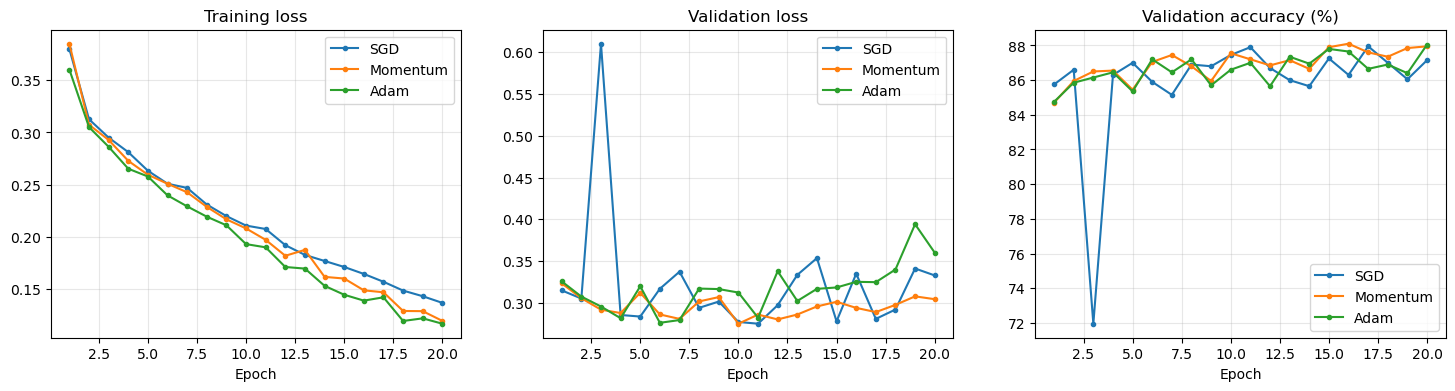

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for name, history in histories.items():
    ep = np.arange(1, epochs + 1)
    axes[0].plot(ep, history["train_loss"], 'o-', ms=3, label=name)
    axes[1].plot(ep, history["val_loss"], 'o-', ms=3, label=name)
    axes[2].plot(ep, np.array(history["val_acc"]) * 100, 'o-', ms=3, label=name)
axes[0].set_title("Training loss")
axes[1].set_title("Validation loss")
axes[2].set_title("Validation accuracy (%)")
for ax in axes:
    ax.set_xlabel("Epoch")
    ax.grid(alpha=0.3)
    ax.legend()
plt.show()

In [12]:
learning_rates = [1e-4, 1e-3, 1e-2, 1e-1, 1]
sensitivity = {"SGD": [], "Adam": []}

for lr in learning_rates:
    for name, Opt in [("SGD", SGD), ("Adam", Adam)]:
        params = init_params(sizes, seed=0)
        with np.errstate(all="ignore"):  # Ignore overflow warnings when training diverges
            params, history = train(params, Opt(params, lr=lr), X_train, Y_train, X_val, Y_val,
                                    batch_size=batch_size, epochs=3, verbose=False)
        sensitivity[name].append(history["val_acc"][-1])
        print(f"{name:5s} lr = {lr:.0e}: val acc = {history['val_acc'][-1]*100:.2f}%")

SGD   lr = 1e-04: val acc = 73.20%


Adam  lr = 1e-04: val acc = 85.45%


SGD   lr = 1e-03: val acc = 82.70%


Adam  lr = 1e-03: val acc = 86.15%


SGD   lr = 1e-02: val acc = 83.35%


Adam  lr = 1e-02: val acc = 85.90%


SGD   lr = 1e-01: val acc = 78.30%


Adam  lr = 1e-01: val acc = 83.45%


SGD   lr = 1e+00: val acc = 51.25%


Adam  lr = 1e+00: val acc = 51.25%


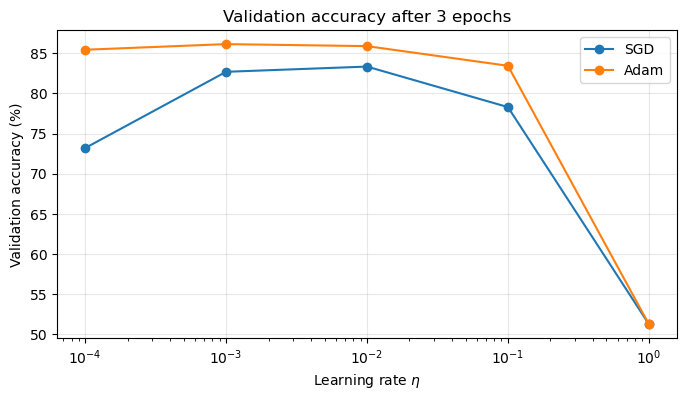

In [13]:
plt.figure(figsize=(8, 4))
for name, accs in sensitivity.items():
    plt.semilogx(learning_rates, np.array(accs) * 100, 'o-', label=name)
plt.xlabel(r"Learning rate $\eta$")
plt.ylabel("Validation accuracy (%)")
plt.title("Validation accuracy after 3 epochs")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

In [14]:
params = trained_params["Adam"]
Y_hat_test, _ = forward(params, X_test)
y_pred = (Y_hat_test[:, 0] >= 0.5).astype(int)

print(f"Test loss: {binary_cross_entropy(Y_hat_test, Y_test):.4f}")
print(f"Test accuracy: {np.mean(y_pred == y_test) * 100:.2f}%")

Test loss: 0.4648
Test accuracy: 86.50%


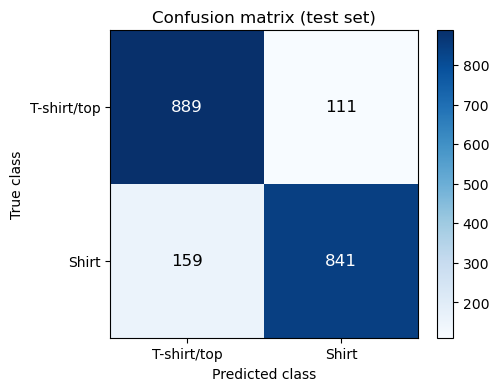

T-shirt/top : accuracy = 88.9%
Shirt       : accuracy = 84.1%


In [15]:
C = np.zeros((2, 2), dtype=int)
for true, pred in zip(y_test, y_pred):
    C[true, pred] += 1

plt.figure(figsize=(5, 4))
plt.imshow(C, cmap="Blues")
for i in range(2):
    for j in range(2):
        plt.text(j, i, C[i, j], ha="center", va="center",
                 color="white" if C[i, j] > C.max() / 2 else "black", fontsize=12)
plt.xticks(range(2), CLASS_NAMES)
plt.yticks(range(2), CLASS_NAMES)
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.title("Confusion matrix (test set)")
plt.colorbar()
plt.show()

for k in range(2):
    print(f"{CLASS_NAMES[k]:12s}: accuracy = {C[k, k] / C[k].sum() * 100:.1f}%")

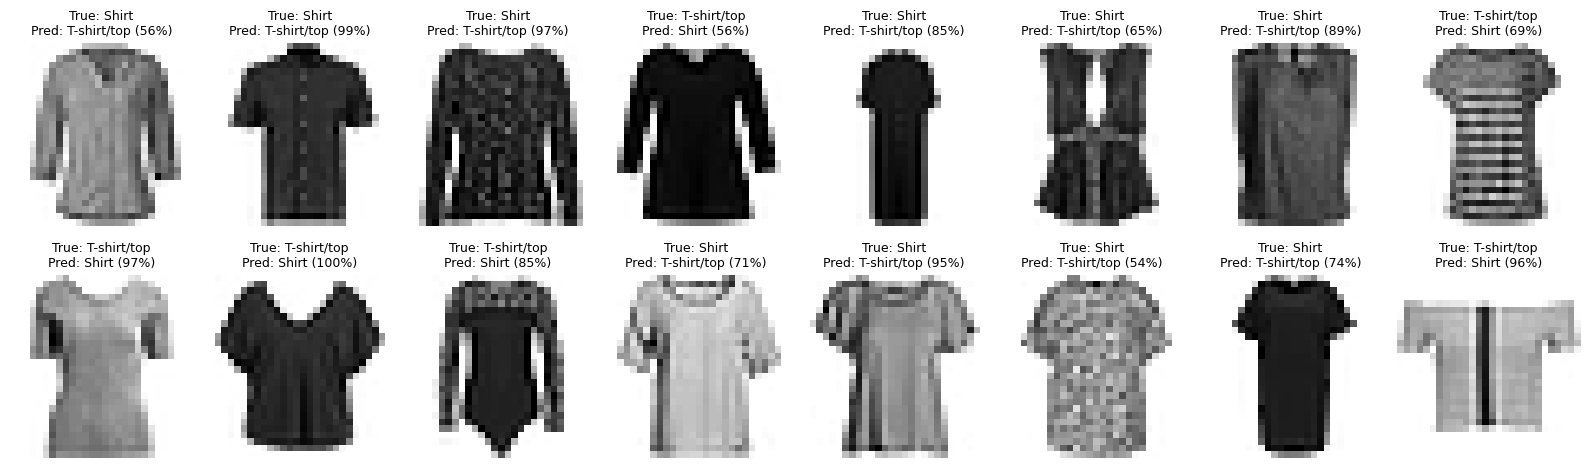

In [16]:
wrong = np.where(y_pred != y_test)[0]
confidence = np.where(y_pred == 1, Y_hat_test[:, 0], 1 - Y_hat_test[:, 0])  # Probability of the predicted class

fig, axes = plt.subplots(2, 8, figsize=(16, 5))
for ax, i in zip(axes.ravel(), wrong[:16]):
    ax.imshow(X_test[i].reshape(28, 28), cmap="gray_r")
    ax.set_title(f"True: {CLASS_NAMES[y_test[i]]}\nPred: {CLASS_NAMES[y_pred[i]]} ({confidence[i]*100:.0f}%)",
                 fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()